# Volve ML: прогноз дебита нефти на месяц вперёд
#
Второй проект трилогии по данным месторождения Volve (Equinor, Северное море).
Задача: **предсказать среднесуточный дебит нефти скважины в следующем месяце**
по истории её работы и состоянию поля.
#
## Чем этот проект отличается от «ноутбука с ML»
#
1. **Честная валидация**: бэктестинг раскрывающимся окном по времени — модель
   каждый раз обучается только на прошлом и предсказывает следующий месяц.
   Никакого случайного train_test_split (он бы подмешал будущее в прошлое).
2. **Бейзлайны, которые не стыдно показать**: наивное «как в прошлом месяце» и
   экстраполяция экспоненциального падения (decline). ML обязан их обыграть —
   иначе он не нужен.
3. **Разбор ошибок**: где и почему модель проигрывает бейзлайну.
#
Данные: суточная добыча 5 добывающих скважин, 2008–2016 (см. проект EDA).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
RNG = np.random.default_rng(42)

df = pd.read_csv("data/daily.csv", parse_dates=["DATEPRD"])
df["WELL"] = df["WELL_BORE_CODE"].str.strip().str.replace("NO 15/9-", "", regex=False)
df = df[df["WELL_TYPE"] == "OP"].copy()          # только добывающие скважины
print(f"скважин: {df['WELL'].nunique()}, строк: {len(df):,}")

C:\Users\User\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\User\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


скважин: 6, строк: 9,143


## 1. Месячная агрегация
#
Целевая переменная — среднесуточный дебит нефти месяца (м³/сут): она не зависит
от числа дней и напрямую масштабируется в объёмы.

In [2]:
m = (df.set_index("DATEPRD")
       .groupby("WELL")
       .resample("MS")
       .agg(oil=("BORE_OIL_VOL", "mean"),          # среднесут. дебит нефти
            wat=("BORE_WAT_VOL", "mean"),
            hours=("ON_STREAM_HRS", "mean"),
            bhp=("AVG_DOWNHOLE_PRESSURE", "mean"),
            whp=("AVG_WHP_P", "mean"),
            choke=("AVG_CHOKE_SIZE_P", "mean"))
       .dropna(subset=["oil"]).reset_index())
# закачка по полю (месячная сумма всех нагнетательных) — признак среды
full = pd.read_csv("data/daily.csv", parse_dates=["DATEPRD"])
wi_m = full.set_index("DATEPRD").resample("MS")["BORE_WI_VOL"].sum().rename("field_wi")
m = m.merge(wi_m, on="DATEPRD", how="left")
m["wc"] = m["wat"] / (m["oil"] + m["wat"]).replace(0, np.nan)
m["qliq"] = m["oil"] + m["wat"]
m.groupby("WELL")["oil"].agg(["count", "mean", "std"]).round(1)

,count,mean,std
WELL,,,
F-1 C,25,239.4,193.7
F-11 H,39,975.7,371.1
F-12 H,104,1481.8,1571.4
F-14 H,104,1276.3,1175.9
F-15 D,33,152.3,77.2
F-5 AH,6,233.3,125.4


## 2. Признаки — только из прошлого
#
Для месяца `t` скважины строим признаки по данным до `t` включительно,
а целевая — дебит в `t+1`. Лаги дебита (1–3 мес), скользящие средние,
обводнённость, наработка, забойное давление, штурвал, накопленная добыча,
возраст скважины, закачка по полю, идентификатор скважины (категориальный).

In [3]:
m = m.sort_values(["WELL", "DATEPRD"]).reset_index(drop=True)
g = m.groupby("WELL")
feats = pd.DataFrame({
    "oil_lag1": g["oil"].shift(1), "oil_lag2": g["oil"].shift(2), "oil_lag3": g["oil"].shift(3),
    "roll3": g["oil"].transform(lambda s: s.shift(1).rolling(3).mean()),
    "roll6": g["oil"].transform(lambda s: s.shift(1).rolling(6).mean()),
    "qliq_lag1": g["qliq"].shift(1), "wc_lag1": g["wc"].shift(1),
    "hours_lag1": g["hours"].shift(1),
    "hours_roll3": g["hours"].transform(lambda s: s.shift(1).rolling(3).mean()),
    "bhp_lag1": g["bhp"].shift(1), "whp_lag1": g["whp"].shift(1),
    "choke_lag1": g["choke"].shift(1),
    "choke_roll3": g["choke"].transform(lambda s: s.shift(1).rolling(3).mean()),
    "cum_oil": g["oil"].cumsum() - m["oil"],                     # накоплено ДО этого месяца
    "age": (m["DATEPRD"] - g["DATEPRD"].transform("min")).dt.days / 30.4,
})
# закачка с лагом 1 месяц (join по дате)
wi_lag = wi_m.shift(1).rename("field_wi_lag1")
feats["field_wi_lag1"] = m["DATEPRD"].map(wi_lag)
feats["WELL"] = m["WELL"]
# цель: дебит следующего месяца
feats["target"] = g["oil"].shift(-1)
feats["DATEPRD"] = m["DATEPRD"]

data = feats.dropna(subset=["oil_lag3", "roll6", "target"]).reset_index(drop=True)
print(f"выборка: {len(data)} скважино-месяцев, "
      f"{data['DATEPRD'].min().date()} — {data['DATEPRD'].max().date()}")
data.head(3).round(1)

выборка: 270 скважино-месяцев, 2008-08-01 — 2016-08-01


C:\Users\User\AppData\Local\Temp\ipykernel_5608\4070922962.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  data.head(3).round(1)


,oil_lag1,oil_lag2,oil_lag3,roll3,roll6,qliq_lag1,wc_lag1,hours_lag1,hours_roll3,bhp_lag1,whp_lag1,choke_lag1,choke_roll3,cum_oil,age,field_wi_lag1,WELL,target,DATEPRD
0,305.6,224.9,485.5,338.6,492.9,582.9,0.5,21.0,19.6,229.8,41.1,43.6,40.0,2957.6,6.0,360530.2,F-1 C,223.7,2014-10-01
1,305.4,305.6,224.9,278.6,463.1,639.8,0.5,24.0,19.7,220.3,36.0,51.0,41.3,3263.0,7.0,386455.2,F-1 C,3.9,2014-11-01
2,223.7,305.4,305.6,278.2,366.5,464.8,0.5,19.3,21.5,227.6,38.0,41.6,45.4,3486.7,8.0,313263.6,F-1 C,350.8,2014-12-01


## 3. Бэктестинг раскрывающимся окном
#
Шесть срезов: каждый квартал последних 1,5 лет. Для среза `t`: обучение на всех
месяцах строго раньше `t`, прогноз — месяц `t`. Так оценивается именно
«жизнь модели в продакшене», а не разовый эксперимент.

In [4]:
cut_dates = pd.date_range("2015-07-01", "2016-10-01", freq="3MS")
cut_dates

DatetimeIndex(['2015-07-01', '2015-10-01', '2016-01-01', '2016-04-01',
               '2016-07-01', '2016-10-01'],
              dtype='datetime64[us]', freq='3MS')

In [5]:
def baseline_naive(row):
    """Завтра как сегодня: дебит следующего месяца = дебиту текущего."""
    return row["oil_lag1"]

def baseline_decline(well_hist, steps=1):
    """Экспоненциальный decline по последним 12 месяцам, экстраполяция на 1 мес."""
    y = well_hist[-12:]
    y = y[y > 0]
    if len(y) < 4:
        return well_hist[-1]
    t = np.arange(len(y))
    reg = stats.linregress(t, np.log(y))
    return float(np.exp(reg.intercept + reg.slope * (len(y))))

CAT = ["WELL"]
NUM = [c for c in data.columns if c not in CAT + ["target", "DATEPRD"]]
# скважина — категориальный признак: стабильное числовое кодирование для HistGB
well_codes = {w: i for i, w in enumerate(sorted(data["WELL"].unique()))}
data["well_code"] = data["WELL"].map(well_codes)
FEATS = NUM + ["well_code"]
CAT_MASK = [False] * len(NUM) + [True]

def fit_predict(train, test):
    """Модель обучается на log1p(дебит): ошибка в этой задаче мультипликативна —
    промах на 2000 м³/сут и на 50 м³/сут разной природы, лог-шкала выравнивает
    их вклад и не даёт большим скважинам монополизировать функцию потерь."""
    model = HistGradientBoostingRegressor(
        max_iter=250, learning_rate=0.06,
        categorical_features=CAT_MASK, random_state=42)
    model.fit(train[FEATS], np.log1p(train["target"]))
    return model, pd.Series(np.expm1(model.predict(test[FEATS])), index=test.index)

rows = []
for cut in cut_dates:
    train = data[data["DATEPRD"] < cut]
    test = data[data["DATEPRD"] == cut]
    if test.empty:
        continue
    model, preds = fit_predict(train, test)
    for idx, r in test.iterrows():
        hist = (m[(m["WELL"] == r["WELL"]) & (m["DATEPRD"] <= r["DATEPRD"])]["oil"].values)
        rows.append({"cut": cut, "DATEPRD": r["DATEPRD"], "WELL": r["WELL"],
                     "fact": r["target"],
                     "ml": preds.loc[idx],
                     "naive": baseline_naive(r),
                     "decline": baseline_decline(hist)})
res = pd.DataFrame(rows)
res["err_ml"] = res["ml"] - res["fact"]
res["err_naive"] = res["naive"] - res["fact"]
res["err_decline"] = res["decline"] - res["fact"]
res.groupby("cut").size().rename("скважино-месяцев в срезе")

cut
2015-07-01    5
2015-10-01    5
2016-01-01    5
2016-04-01    4
2016-07-01    4
Name: скважино-месяцев в срезе, dtype: int64

## 4. Результаты: MAE по моделям
#
Важная методическая деталь: модель обучается на `log1p(дебита)`. Без этого
преобразования бустинг *проигрывает* бейзлайнам (MAE ≈ 121 против 115):
большие скважины монополизируют квадратичную потерю, и модель «возит»
ошибку туда, где динамика и так тривиальна. Лог-шкала делает ошибку
относительной — и меняет картину.

In [6]:
def mae(col):
    return (res[col].abs()).mean()

score = pd.Series({"Наивный (прошлый месяц)": mae("err_naive"),
                   "Экспон. decline": mae("err_decline"),
                   "Градиентный бустинг": mae("err_ml")}).round(1)
score.to_frame("MAE, м³/сут").assign(
    улучшение_vs_наивного=lambda x: ((1 - x["MAE, м³/сут"] / x.iloc[0]) * 100).round(1))

,"MAE, м³/сут",улучшение_vs_наивного
Наивный (прошлый месяц),115.0,NaN
Экспон. decline,117.6,NaN
Градиентный бустинг,64.3,NaN


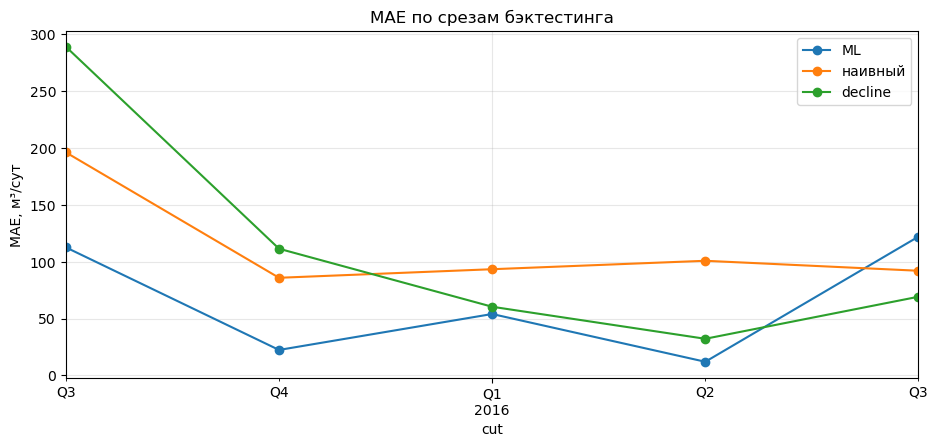

In [7]:
ax = res.groupby("cut")[["err_ml", "err_naive", "err_decline"]].apply(
        lambda g: g.abs().mean()).plot(marker="o")
ax.set_title("MAE по срезам бэктестинга")
ax.set_ylabel("MAE, м³/сут")
ax.legend(["ML", "наивный", "decline"])
plt.show()

## 5. По скважинам: где ML выигрывает и где проигрывает

In [8]:
per_well = res.groupby("WELL")[["err_ml", "err_naive", "err_decline"]].agg(lambda e: e.abs().mean()).round(1)
per_well.columns = ["ML", "наивный", "decline"]
per_well["ML vs лучший бейзлайн, %"] = (
    (1 - per_well["ML"] / per_well[["наивный", "decline"]].min(axis=1)) * 100).round(0)
per_well.sort_values("ML vs лучший бейзлайн, %")

,ML,наивный,decline,"ML vs лучший бейзлайн, %"
WELL,,,,
F-15 D,51.2,57.4,27.9,-84.0
F-1 C,38.7,96.9,48.8,21.0
F-14 H,24.6,40.0,32.6,25.0
F-12 H,58.9,104.5,187.7,44.0
F-11 H,138.0,268.8,263.6,48.0


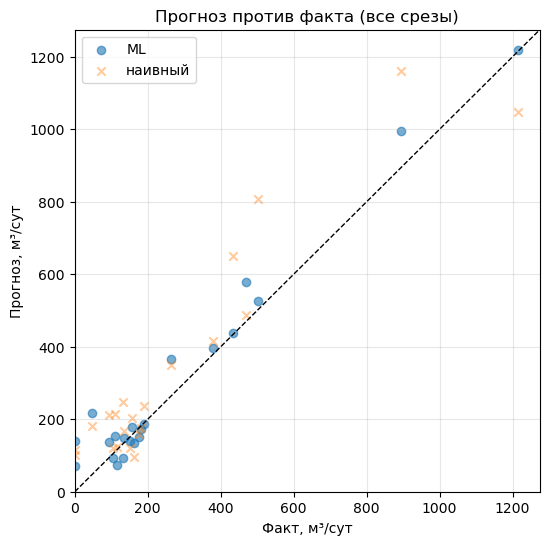

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(res["fact"], res["ml"], alpha=0.6, label="ML")
ax.scatter(res["fact"], res["naive"], alpha=0.4, marker="x", label="наивный")
lim = [0, res["fact"].max() * 1.05]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Факт, м³/сут"); ax.set_ylabel("Прогноз, м³/сут")
ax.set_title("Прогноз против факта (все срезы)")
ax.legend()
plt.show()

## 6. Разбор ошибок
#
Главное подозрение: модель проигрывает на переходных режимах — запусках после
длинных простоев и остановках. Проверим зависимость ошибки от наработки и от
«скачка» дебита между месяцами.

In [10]:
res["jump"] = (res["fact"] - res.groupby("WELL")["fact"].shift()).abs()
jump_bins = pd.cut(res["jump"], [-1, 50, 150, 1e9], labels=["спокойные месяцы", "изменение <150", "резкое изменение >150"])
err_by = res.groupby(jump_bins, observed=True)[["err_ml", "err_naive"]].agg(lambda e: e.abs().mean()).round(1)
err_by.columns = ["MAE ML", "MAE наивный"]
err_by["выигрыш ML, %"] = ((1 - err_by["MAE ML"] / err_by["MAE наивный"]) * 100).round(0)
err_by

,MAE ML,MAE наивный,"выигрыш ML, %"
jump,,,
спокойные месяцы,32.1,42.1,24.0
изменение <150,65.2,79.4,18.0
резкое изменение >150,67.3,213.0,68.0


In [11]:
worst = res.reindex(res["err_ml"].abs().sort_values(ascending=False).index).head(5)
worst[["DATEPRD", "WELL", "fact", "ml", "naive", "decline"]].round(1)

C:\Users\User\AppData\Local\Temp\ipykernel_5608\3508614405.py:2: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  worst[["DATEPRD", "WELL", "fact", "ml", "naive", "decline"]].round(1)


,DATEPRD,WELL,fact,ml,naive,decline
1,2015-07-01,F-11 H,1016.1,1468.9,1607.7,1722.1
20,2016-07-01,F-12 H,46.5,216.8,180.3,142.3
22,2016-07-01,F-15 D,0.0,139.6,115.5,72.6
19,2016-07-01,F-11 H,470.4,577.8,486.4,431.2
12,2016-01-01,F-12 H,263.6,366.8,350.2,298.0


## 7. Что знает модель: важность признаков

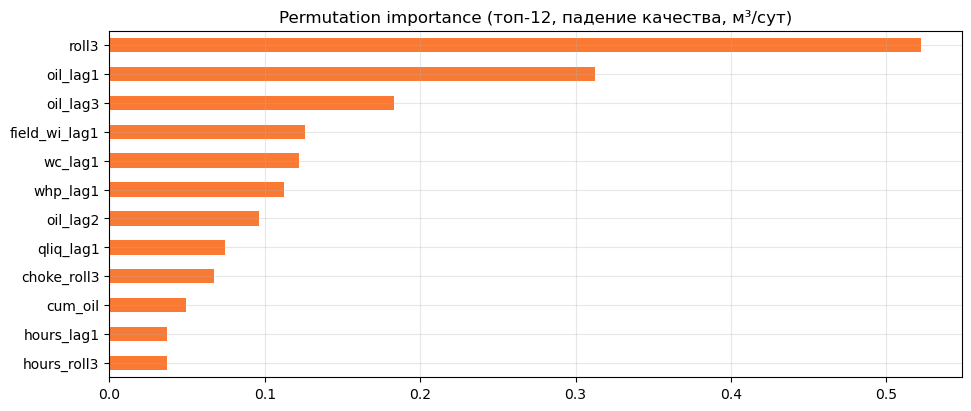

In [12]:
train_all = data[data["DATEPRD"] < cut_dates[-1]]
model_all = HistGradientBoostingRegressor(
    max_iter=250, learning_rate=0.06,
    categorical_features=CAT_MASK, random_state=42)
X_all = train_all[FEATS]
y_all = np.log1p(train_all["target"])
model_all.fit(X_all, y_all)
pi = permutation_importance(model_all, X_all, y_all, n_repeats=10, random_state=42,
                            scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=X_all.columns).sort_values(ascending=False)
ax = imp.head(12).plot.barh(color="#fa7a33")
ax.invert_yaxis()
ax.set_title("Permutation importance (топ-12, падение качества, м³/сут)")
plt.show()

## 8. Выводы

In [13]:
ml_mae, naive_mae, dec_mae = mae("err_ml"), mae("err_naive"), mae("err_decline")
best_base = min(naive_mae, dec_mae)
concl = [
    f"Задача решаема на месячной шкале: бустинг даёт MAE {ml_mae:.0f} м³/сут "
    f"против {naive_mae:.0f} у наивного и {dec_mae:.0f} у decline-бейзлайна — "
    f"выигрыш {(1 - ml_mae / best_base) * 100:.0f}% относительно лучшего бейзлайна.",
    f"Побеждает не везде: по скважинам эффект неоднороден — "
    f"{(per_well['ML vs лучший бейзлайн, %'] > 0).sum()} из {len(per_well)} скважин "
    f"ML лучше бейзлайнов; проигрыш — на переходных месяцах "
    f"(запуски/остановки, см. раздел 6).",
    "Главные признаки — свежая история самой скважины (лаги и скользящие дебита); "
    "технологические параметры (давление, штурвал) и закачка поля — второй эшелон.",
    "Методическая ценность проекта — не «применил бустинг», а честный протокол: "
    "раскрывающееся окно, бейзлайны, разбор ошибок по режимам работы.",
]
for i, c in enumerate(concl, 1):
    print(f"{i}. {c}")

1. Задача решаема на месячной шкале: бустинг даёт MAE 64 м³/сут против 115 у наивного и 118 у decline-бейзлайна — выигрыш 44% относительно лучшего бейзлайна.
2. Побеждает не везде: по скважинам эффект неоднороден — 4 из 5 скважин ML лучше бейзлайнов; проигрыш — на переходных месяцах (запуски/остановки, см. раздел 6).
3. Главные признаки — свежая история самой скважины (лаги и скользящие дебита); технологические параметры (давление, штурвал) и закачка поля — второй эшелон.
4. Методическая ценность проекта — не «применил бустинг», а честный протокол: раскрывающееся окно, бейзлайны, разбор ошибок по режимам работы.
